# R5 · Suites — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/r5_suites/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | R5.1 à R5.8, R5.11, R5.12 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | R5.14 | Terme d'une suite arithmétique et somme géométrique · `arithmetic_term`, `geometric_sum` | 🔨 | ★ | 15 |
|  | R5.15 | Itérer une récurrence · `iterate` | 🔨 | ★ | 15 |
|  | R5.16 | Moyennes mobile et exponentielle · `moving_average`, `exponential_moving_average` | 🔨 | ★★ | 25 |
| B | R5.17 | Les mêmes calculs avec NumPy : `np.cumsum`, `np.cumprod`, `np.convolve` | 📦 | ★ | 15 |
|  | R5.18 | Prédire : vers quoi tend u(n + 1) = 0,75 u(n) + 2 ? | 🔮 | ★ | 10 |
|  | R5.19 | Lisser un signal bruité : l'effet de la fenêtre et de β | 🔬 | ★★ | 20 |
|  | R5.20 | Des suites qui convergent, divergent, oscillent | 🎨 | ★ | 15 |
| C | R5.21 | Chasse à l'erreur : un décalage d'indice dans une somme | 🐛 | ★ | 15 |
|  | R5.22 | Une boucle ou une formule ? Mesurer le temps de calcul | 🛠️ | ★ | 15 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : termes, raisons, sommes, sommes infinies, intérêts composés, moyennes mobiles et exponentielles.
- Écrire les cinq fonctions de `mymath/sequences.py` et les tester.
- Refaire ces calculs avec NumPy, prédire le comportement d'une récurrence, régler un lissage, tracer des suites, chasser un décalage d'indice et chronométrer une formule.

**Rappel express.** Arithmétique : $u_n = u_0 + n\,r$ ; géométrique : $u_n = u_0\,q^n$. Somme arithmétique : nombre de termes × (premier + dernier) / 2 ; somme géométrique de $n$ termes : premier × $\frac{1 - q^n}{1 - q}$ ($q \ne 1$). Si $\lvert q \rvert < 1$ : $q^n \to 0$ et la somme infinie vaut premier ÷ $(1 - q)$. Moyenne exponentielle : $v_0 = 0$, $v_t = \beta\,v_{t-1} + (1 - \beta)\,x_t$.

## Partie 0 · Vérifier tes exercices papier (✏️ R5.1 à R5.8, 🔗 R5.11 et R5.12)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un nombre avec un point décimal, `-1.5`, arrondi comme le demande la question ;
- une fraction exacte entre guillemets, `"5/7"` ;
- une expression en `n` entre guillemets, `"3*n**2 + 1"` (`*` pour multiplier, `**` pour la puissance) ;
- une liste de nombres entre crochets, dans l'ordre demandé ;
- vrai ou faux par `True` ou `False` ; un numéro de réponse proposée par un entier.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
from fractions import Fraction


def u1(n):                                                    # R5.1
    return n * n - 3 * n + 1


def by_rule(rule, first, steps):
    """[first, rule(first), …]: steps + 1 terms of a sequence defined by recursion."""
    terms = [first]
    for _ in range(steps):
        terms.append(rule(terms[-1]))
    return terms


W = {1: 1}                                                    # w₁ = 1, w_{n+1} = w_n + 2n + 1
for n in range(1, 6):
    W[n + 1] = W[n] + 2 * n + 1


def ema(values, beta, v=0.0):                                 # R5.7
    averages = []
    for x in values:
        v = beta * v + (1 - beta) * x
        averages.append(round(v, 10))
    return averages


def window_means(values, k):                                  # R5.7, R5.12
    return [sum(values[i:i + k]) / k for i in range(len(values) - k + 1)]


def present_value(payment, rate, years, first=1):             # R5.11: payments at the end of years first, first + 1…
    return sum(payment / (1 + rate) ** k for k in range(first, first + years))


X7 = [10, 20, 15, 5, 25]
X12 = [12, 18, 15, 9, 21, 24, 6, 15]

**Ex R5.1 — Calculer des termes : explicite et récurrence**

In [3]:
wbm.record("R5.1a", u1(5), mistakes={"u₅ est le terme de rang 5 : remplace n par 5 (le rang, pas la place dans la liste u₀, u₁, …)": u1(4), "remplace n par 5 partout, puis respecte les priorités : la puissance, puis les produits": 9})
wbm.record("R5.1b", u1(10), mistakes={"u₁₀ est le terme de rang 10 : remplace n par 10": u1(9)})
wbm.record("R5.1c", by_rule(lambda v: 2 * v - 4, 3, 3)[1:], mistakes={"la liste commence à v₁ = 2 × v₀ − 4 : v₀ n'en fait pas partie": by_rule(lambda v: 2 * v - 4, 3, 3)[:3], "2vₙ − 4 : on multiplie vₙ par 2, puis on retire 4 (pas 2 × (vₙ − 4))": by_rule(lambda v: 2 * (v - 4), 3, 3)[1:]})
wbm.record("R5.1d", W[4], mistakes={"pour calculer w₂, on prend n = 1 dans la règle : w₂ = w₁ + 2 × 1 + 1": 22, "w₄ : trois pas depuis w₁, qui est le premier terme": {W[3], W[5]}})
wbm.record("R5.1e", "n**2", kind="expr", variables=("n",), mistakes={"vérifie ta formule en n = 1 : elle doit donner w₁ = 1": "(n + 1)**2", "vérifie ta formule en n = 2 : elle doit donner w₂": "(n - 1)**2", "vérifie ta formule sur w₁, w₂, w₃ et w₄ : elle doit les donner tous": "n**2 + 1", "2n + 1 est l'écart entre deux termes, pas le terme lui-même": "2*n + 1"})
wbm.record("R5.1f", "2*n - 2", kind="expr", variables=("n",), mistakes={"(n + 1)² = n² + 2n + 1, pas n² + 1": "-2", "−3(n + 1) = −3n − 3 : le −3 multiplie aussi le 1": "2*n + 1", "on calcule u_{n+1} − uₙ, dans cet ordre": "2 - 2*n"})
wbm.record("R5.1g", 1, mistakes={"compare u₁ et u₀ : la suite commence par diminuer": 0, "u_{n+1} ≥ uₙ est une inégalité large : un cas d'égalité convient": 2})

WBM_ANSWER {"hash": "c3b079027b4b0b31fadc2ab53ce1547568504d29f0e5b789aa41743c5dd1a826", "id": "R5.1a", "kind": "int", "magnitude": 1, "mistakes": {"82311ea7c8292fd72a5f588b80ce557f714a3a0af9f2e3a5e91f5aeb98d6afa6": "remplace n par 5 partout, puis respecte les priorités : la puissance, puis les produits", "e58facf179c4e7adfa8a0d9fde4fb4b29cc456c0a236752a44861f09c963be9a": "u₅ est le terme de rang 5 : remplace n par 5 (le rang, pas la place dans la liste u₀, u₁, …)"}, "sign": 1}
📝 Ex R5.1a : réponse enregistrée (int).
WBM_ANSWER {"hash": "085fdd8174dd47c9de4d2345df8476a158de74dd1f7cff1c0aded7ea5eb8daa4", "id": "R5.1b", "kind": "int", "magnitude": 1, "mistakes": {"9ef8f3382311cdeae8926e341e8ba6a5aefc6d5efedd89b514c3aa209a3c4ed4": "u₁₀ est le terme de rang 10 : remplace n par 10"}, "sign": 1}
📝 Ex R5.1b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["6ab7ee1f71e7f68d1cbd58d852f0b2b93f24c5fe982f208322938f2083ee1136", "e91df3b7e428e217db7343e3f493ffb13bfa72c275ed1

WBM_ANSWER {"hash": "72b2fba42720883a835ead11e8931f5295dd9fa85fd5062c4200be1fd5f1c1c8", "id": "R5.1e", "kind": "expr", "mistakes": {"0f10f9e930736219bea41cbf46ef34f048cc29150524cbb3e2c8eb9bf895671e": "vérifie ta formule en n = 1 : elle doit donner w₁ = 1", "3524b73915cb2d42cd5267fee8e0597fb86bff0ebff01777f39a15622aa5e37c": "vérifie ta formule en n = 2 : elle doit donner w₂", "bbd8983411c9d896f6639615ec470e640ca06b6781a28b927329a700f889a500": "2n + 1 est l'écart entre deux termes, pas le terme lui-même", "dd381dc008cd713df16a3fdcfa2be1f508d3b28a6be63ef10a1bad9055602a8f": "vérifie ta formule sur w₁, w₂, w₃ et w₄ : elle doit les donner tous"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["n"]}
📝 Ex R5.1e : réponse enregistrée (expr).
WBM_ANSWER {"hash": "7393c3c8c5d9c4d35f92eace1f3b71e17b489b1d1b2d830d782853d8dcc6d250", "id": "R5.1f", "kind": "expr", "mistakes": {"3b6d2bc8d1d459cd6930cc09e4b877751accc885f29dd9af3bb00fb878d3bdb7": "on calcule u_{n+1} − uₙ, dans c

**Ex R5.2 — Terme général d'une suite arithmétique**

In [4]:
wbm.record("R5.2a", "7 + 4*n", kind="expr", variables=("n",), mistakes={"uₙ = u₀ + n r : le premier terme est 7, la raison 4": "4 + 7*n", "la suite commence au rang 0 : uₙ = u₀ + n r": "7 + 4*(n - 1)", "une suite arithmétique ajoute la raison : pas de puissance": "7*4**n"})
wbm.record("R5.2b", 7 + 4 * 25, mistakes={"u₂₅ : on ajoute 25 fois la raison à u₀": {7 + 4 * 24, 7 + 4 * 26}})
wbm.record("R5.2c", -13.0, decimals=2, mistakes={"la suite commence au rang 1 : aₙ = a₁ + (n − 1) r": {12 - 2.5 * 11, 12 - 2.5 * 12}, "la raison est négative : chaque pas retire 2,5": 12 + 2.5 * 10})
wbm.record("R5.2d", next(n for n in range(1, 100) if 12 - 2.5 * (n - 1) < 0), fractional="un rang est un entier : le premier entier qui convient", mistakes={"aₙ = a₁ + (n − 1) r : calcule le terme de ce rang, il est encore positif ou nul": {4, 5}, "il y a un rang plus petit qui convient : calcule les termes un par un": 7})
wbm.record("R5.2e", (2023 - 7) // 4, mistakes={"la suite commence au rang 0 : résous 7 + 4n = 2 023": 505, "n est un rang : résous 7 + 4n = 2 023, puis vérifie avec u_n": {2016, 2023}})
wbm.record("R5.2f", (2026 - 7) % 4 == 0, mistakes={"résous 7 + 4n = 2 026 : n doit être un entier": True})
wbm.record("R5.2g", int(24 / 1.5), mistakes={"compte la hauteur restante heure par heure : elle n'est pas encore nulle": 15, "la bougie est consumée quand sa hauteur est nulle : pas une heure de plus": 17, "combien de fois 1,5 cm tiennent-ils dans 24 cm ? On divise": 36})

WBM_ANSWER {"hash": "c112d42a254a9df9f58393ce6d9fc9da9a56adbc3ab0a85f6a22edaf4d6439f0", "id": "R5.2a", "kind": "expr", "mistakes": {"149b502c6620e5babe0b50f4a6af17b2d0352dfef445a676f23fc844848b220c": "uₙ = u₀ + n r : le premier terme est 7, la raison 4", "2b3cc936b86fb6e15a96de8197ed0b81c791e9a356aa559d3b1fffbb99161105": "la suite commence au rang 0 : uₙ = u₀ + n r", "f85a11ee8c26da6bfc755a7cdd75104893d81bd54c24ac751007f51b0a52a980": "une suite arithmétique ajoute la raison : pas de puissance"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["n"]}
📝 Ex R5.2a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "e4496de56d96aa2b8724cb5bfae63a078d70407e9f12afa3a1305fb1af0828b5", "id": "R5.2b", "kind": "int", "magnitude": 2, "mistakes": {"729aa905621c709db69424b33c27a565b3b1d54134564105373e05c5b4a7bb0a": "u₂₅ : on ajoute 25 fois la raison à u₀", "fb21125e2a62c32b7e465f59881fe7a0a700b82ee734b845a89cfab4120494a5": "u₂₅ : on ajoute 25 fois la raison à u₀"}, "sign": 1}
📝

**Ex R5.3 — Terme général d'une suite géométrique**

In [5]:
wbm.record("R5.3a", "5*3**n", kind="expr", variables=("n",), mistakes={"le premier terme multiplie, la raison est à la puissance n": "3*5**n", "5 × 3ⁿ n'est pas (5 × 3)ⁿ : la puissance ne porte que sur la raison": "15**n", "la suite commence au rang 0 : vₙ = v₀ qⁿ": "5*3**(n - 1)", "une suite géométrique multiplie par la raison : on n'ajoute pas": "5 + 3*n", "une suite géométrique : la raison est à la puissance n, elle ne multiplie pas n": "15*n"})
wbm.record("R5.3b", 5 * 3**4, mistakes={"v₄ : quatre multiplications par 3 depuis v₀": {5 * 3**3, 5 * 3**5}, "3⁴, pas 3 × 4": 60, "5 × 3⁴ n'est pas (5 × 3)⁴": 15**4})
wbm.record("R5.3c", float(64 * Fraction(3, 4) ** 3), decimals=2, mistakes={"la suite commence au rang 1 : wₙ = w₁ q^(n − 1)": {64 * 0.75**4, 64 * 0.75**2}})
wbm.record("R5.3d", 64 * Fraction(3, 4) ** 6, kind="fraction", mistakes={"la suite commence au rang 1 : wₙ = w₁ q^(n − 1), donc une puissance de moins que le rang": "2187/256", "w₇ = w₁ q^(7 − 1) : six multiplications par la raison": "243/16"})
wbm.record("R5.3e", round(500 * 1.2**3, 2), decimals=2, mistakes={"chaque heure, on multiplie par 1,2 : les hausses se composent": 800, "p₃ : trois heures, trois multiplications par 1,2": {720, round(500 * 1.2**4, 1)}})
wbm.record("R5.3f", 2 * (-3) ** 5, mistakes={"une puissance impaire d'un nombre négatif est négative": 486, "t₅ : cinq multiplications par −3 depuis t₀": {2 * (-3) ** 4, 2 * (-3) ** 6}})
wbm.record("R5.3g", next(n for n in range(50) if 500 * 1.2**n > 2000), fractional="un nombre d'heures entier : le premier entier qui convient, pas un arrondi", mistakes={"calcule p₇ : la population n'a pas encore dépassé 2 000": 7, "les hausses se composent : on multiplie par 1,2 chaque heure, on n'ajoute pas 100": 16})

WBM_ANSWER {"hash": "19de95e231ae9a533e3cd6cc39aa5e5791cc75bd9f6e3ac9c6ca07557529376f", "id": "R5.3a", "kind": "expr", "mistakes": {"02cee5d00d061a3721d8a613d0d25ba3b25644ad1eb70d89a1ff28d89e48cd16": "une suite géométrique : la raison est à la puissance n, elle ne multiplie pas n", "35b7790dd17f7cf9e1a146f09b5f72986802a73b8fa83e93f1c1c1bce96d167e": "la suite commence au rang 0 : vₙ = v₀ qⁿ", "52f092bbbedd94fa0cae800b29dfc0f0548d22f27c1fa7a101a224dd87731f0a": "une suite géométrique multiplie par la raison : on n'ajoute pas", "a80a00b141cd532d70ecf5943bb2985f61d630d6670863ceb7492920127d5da3": "le premier terme multiplie, la raison est à la puissance n", "c29e82cee2083601fbeb96c6d723f2333b2c130acc94a3fd403c908370737382": "5 × 3ⁿ n'est pas (5 × 3)ⁿ : la puissance ne porte que sur la raison"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["n"]}
📝 Ex R5.3a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "e5d8928e262f061ebe2984d1df89a2ebe14cd3c0b70209c2001fab420a53

**Ex R5.4 — Sommes arithmétiques et géométriques**

In [6]:
wbm.record("R5.4a", len(range(5, 51, 3)), mistakes={"de 5 à 50 par pas de 3 : il y a un terme de plus que d'écarts": 15})
wbm.record("R5.4b", float(sum(range(5, 51, 3))), decimals=2, mistakes={"compte les termes : un de plus que d'écarts": {15 * 55 / 2, 17 * 55 / 2}, "nombre de termes × (premier + dernier), divisé par 2": 16 * 55})
wbm.record("R5.4c", sum(2 + 0.5 * k for k in range(20)), decimals=2, mistakes={"de k = 0 à 19 : 20 termes": {19 * 13.5 / 2, 21 * 13.5 / 2}, "le dernier terme est celui de k = 19 : 2 + 0,5 × 19": 20 * 14 / 2, "la somme des k va de 0 à 19, pas de 1 à 20": 20 * 2 + 0.5 * 210})
wbm.record("R5.4d", sum(4**k for k in range(6)), mistakes={"de 4⁰ à 4⁵ : 6 termes, donc 4⁶ dans la formule": {(4**5 - 1) // 3, (4**7 - 1) // 3}, "(qⁿ − 1)/(q − 1) : n'oublie pas de diviser par q − 1 = 3": 4**6 - 1})
wbm.record("R5.4e", 81.0 + 54 + 36 + 24 + 16, decimals=2, mistakes={"compte les termes : il y en a cinq": {195, round(243 * (1 - (2 / 3) ** 6), 2)}, "la raison est le quotient d'un terme par le précédent : 54/81": 81 * (1 - 1.5**5) / (1 - 1.5)})
wbm.record("R5.4f", sum(2**k for k in range(3, 9)), mistakes={"la somme commence à k = 3 : son premier terme est 2³": {2**9 - 1, 2**6 - 1}, "de k = 3 à 8, il y a 8 − 3 + 1 termes": {8 * 31, 8 * 127}})
wbm.record("R5.4g", sum((-2) ** k for k in range(10)), mistakes={"(−2)¹⁰ est positif : 1 − (−2)¹⁰ = 1 − 1 024": 341, "la raison est −2 : 1 − q = 1 + 2": 1023, "de k = 0 à 9 : 10 termes, donc (−2)¹⁰ dans la formule": {683, 171}})
wbm.record("R5.4h", "n**2 + 2*n", kind="expr", variables=("n",), mistakes={"de k = 0 à n − 1, la somme des k vaut (n − 1)n/2": "n**2 + 4*n", "la somme s'arrête à k = n − 1 : n termes, pas n + 1": "n**2 + 4*n + 3", "la constante 3 est ajoutée n fois": "n**2 - n + 3", "le dernier terme est celui de k = n − 1 : 3 + 2(n − 1)": "n**2 + 3*n"})

WBM_ANSWER {"hash": "c9dcfe7e21b62ffe9989ceb8e147bebabdab9d5bc95689843e775fb30b347fff", "id": "R5.4a", "kind": "int", "magnitude": 1, "mistakes": {"8a175ffdfc067851956dfcf48c766b91da7298de36df11c29f3c4204c708e913": "de 5 à 50 par pas de 3 : il y a un terme de plus que d'écarts"}, "sign": 1}
📝 Ex R5.4a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["a0a6a77afe59baf6bbf7e1890ea0a3b3b523116fcbc33c2cf1c8aeecce7a07bc"]}, "decimals": 2, "hash": "2cb9874097e79a58e528bcd0e05df044c6f486551469fbe624222c9ce81641c4", "hash_coarse": "59ac458c0aec083aed8bb5ccd0dd5ce8518b5b3babe9c2f0607990043fa407cc", "id": "R5.4b", "kind": "float", "magnitude": 2, "mistakes": {"44e19ee320672e015658395edf530459ac17a2c148226739e9433657fa1d6735": "compte les termes : un de plus que d'écarts", "9a49fd1312c799a883fd25a4b23599ea86e257234c9d238df2b9f9ae69fe1057": "nombre de termes × (premier + dernier), divisé par 2", "c82e30e6206b43f34c6a460035ee65591c83685f4a73ae235e5611a17cb1ead3": "compte les termes : un

**Ex R5.5 — Sommes infinies d'une suite géométrique**

In [7]:
wbm.record("R5.5a", int(1 / (1 - Fraction(3, 4))), mistakes={"la somme commence à k = 0 : son premier terme est 1": 3})
wbm.record("R5.5b", 2 / (1 - Fraction(1, 5)), kind="fraction", mistakes={"la raison est le quotient de deux termes consécutifs : (2/5) ÷ 2": "10/3", "premier terme ÷ (1 − raison) : le premier terme est 2": "5/4"})
wbm.record("R5.5c", 9 / (1 + Fraction(2, 3)), kind="fraction", mistakes={"la raison est négative : −6/9 = −2/3, donc 1 − q = 1 + 2/3": "27", "premier terme ÷ (1 − raison) : le premier terme est 9": "3/5"})
wbm.record("R5.5d", Fraction(3, 10) / (1 - Fraction(3, 10)), kind="fraction", mistakes={"la somme commence à k = 1 : son premier terme est 0,3, pas 1": "10/7"})
wbm.record("R5.5e", False, mistakes={"la raison 1,1 est plus grande que 1 : les termes grandissent, et les sommes partielles aussi": True})
wbm.record("R5.5f", next(n for n in range(1, 100) if 4 - 4 * (1 - 0.75**n) < 0.1), fractional="un nombre de termes est entier : le premier entier qui convient, pas un arrondi", mistakes={"pour ce nombre de termes, l'écart à la limite est encore supérieur à 0,1": 12, "l'écart entre la limite et la somme partielle vaut premier terme × qⁿ / (1 − q) (fiche §5)": 9, "un nombre de termes plus petit convient déjà : essaie les valeurs une par une": 14})

WBM_ANSWER {"hash": "6b65dfc39ee076512b26d7bb40b39b1b427e8a31ff3cdcd21d0fdcff8e350ad2", "id": "R5.5a", "kind": "int", "magnitude": 0, "mistakes": {"de37244b5eab9b58370ae98cea4812f5b7d7d1f56662603baca2b17dcb147c0d": "la somme commence à k = 0 : son premier terme est 1"}, "sign": 1}
📝 Ex R5.5a : réponse enregistrée (int).
WBM_ANSWER {"hash": "be00aa9d31e8070283c520c1da3617471550e387efa5663e4f0d06b018c62bcf", "id": "R5.5b", "kind": "fraction", "mistakes": {"601ee6f7710e15672006bfa89d9da10b7b987e484ef070b1559db85cfc300c03": "premier terme ÷ (1 − raison) : le premier terme est 2", "d4866f5f6e28e003e31b69733cb691cf644f01a3efbd3ae2f73af18df8128283": "la raison est le quotient de deux termes consécutifs : (2/5) ÷ 2"}, "sign": 1}
📝 Ex R5.5b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "86e8848a65194745e69438beb997f71b1563eb64e87b91ba0b97091bac6f304b", "id": "R5.5c", "kind": "fraction", "mistakes": {"6bdafb3b7ce65174b5b19f2dc34820275327677614decf169593c7f4ed9db15f": "la raison est négat

**Ex R5.6 — Intérêts composés et actualisation**

In [8]:
wbm.record("R5.6a", 3075, mistakes={"le capital, pas seulement les intérêts de l'année": 75})
wbm.record("R5.6b", round(3000 * 1.025**10, 2), decimals=2, mistakes={"les intérêts se composent : on multiplie par 1,025 chaque année": 3750, "10 ans : dix multiplications par 1,025": {round(3000 * 1.025**9, 2), round(3000 * 1.025**11, 2)}})
wbm.record("R5.6c", 3000.0 + 10 * 75, decimals=2, mistakes={"à intérêts simples, les intérêts sont les mêmes chaque année : 2,5 % du capital de départ": round(3000 * 1.025**10, 2)})
wbm.record("R5.6d", next(n for n in range(100) if 3000 * 1.025**n > 4000), fractional="un nombre d'années pleines : le premier entier qui convient, pas un arrondi", mistakes={"calcule le capital au bout de ce nombre d'années : il n'a pas encore dépassé 4 000 €": 11, "les intérêts se composent : on multiplie par 1,025 chaque année": 14})
wbm.record("R5.6e", round(5000 / 1.025**6, 2), decimals=2, mistakes={"actualiser, c'est diviser par 1,025⁶, pas multiplier": round(5000 * 1.025**6, 2), "on divise par 1,025⁶ : on ne retire pas six fois des intérêts simples": 4250})
wbm.record("R5.6f", round((1.01**12 - 1) * 100, 2), decimals=2, mistakes={"1 % par mois se compose : le coefficient annuel est 1,01¹²": 12, "la hausse en pourcentage, pas le coefficient multiplicateur : (coefficient − 1) × 100": {round(1.01**12, 4), round(1.01**12 * 100, 2)}})
wbm.record("R5.6g", True, mistakes={"1/1,025ⁿ = (1/1,025)ⁿ : une suite géométrique de raison comprise entre 0 et 1": False})

WBM_ANSWER {"hash": "5ff259ede19d6bac945ced93bfcb861539349d371263499b6c27a8a36a825c5e", "id": "R5.6a", "kind": "int", "magnitude": 3, "mistakes": {"6e938f8acfa2aa945aa47ca85b5d1be040402f4cf9b66d785d9c9bd835805509": "le capital, pas seulement les intérêts de l'année"}, "sign": 1}
📝 Ex R5.6a : réponse enregistrée (int).
WBM_ANSWER {"alt_coarse": ["82ed8dc8a0e53d0aa0a49655db698e78ff19d83398e6e95eaf035e12da5202b7"], "coarse_any": {"0": ["7632607473bfa182816d7e3ce00274aea8b51da567b1fc5d8978b515c07a6f0b"]}, "decimals": 2, "hash": "a2745fea171a87fa3350f477c71bca9f2d02afe7363d6ea6c09e77700765a1f0", "hash_coarse": "870c5226057901fc00332baf42c774740304484ce7ae944bebbda145e4ffa921", "id": "R5.6b", "kind": "float", "magnitude": 3, "mistakes": {"2b1b17343e6caad63b3f085eb4df883b30a38125d9f78d86e3c32de3c9966b28": "10 ans : dix multiplications par 1,025", "78e74e2afa0003883a203be48f4b6945c4ec557dc0a05d91c6cc840569cb5e97": "10 ans : dix multiplications par 1,025", "80a7e9d7fa931bdce722f5d3b517b13ecc43b

**Ex R5.7 — Une moyenne exponentielle à la main sur cinq valeurs**

In [9]:
wbm.record("R5.7a", ema(X7, 0.8), decimals=4, mistakes={"0,8 multiplie l'ancienne moyenne, 0,2 la nouvelle valeur": ema(X7, 0.2), "v₀ = 0, pas x₁ : la moyenne part de 0": ema(X7, 0.8, 10.0), "la liste commence à v₁ : v₀ = 0 n'en fait pas partie": [0] + ema(X7, 0.8)[:4]})
wbm.record("R5.7b", window_means(X7, 3), decimals=2, mistakes={"5 valeurs et une fenêtre de 3 : 5 − 3 + 1 moyennes": window_means(X7, 3)[:2], "une moyenne : divise chaque somme par 3": [3 * m for m in window_means(X7, 3)]})
wbm.record("R5.7c", sum(X7) // 5, mistakes={"une moyenne : divise la somme par 5": sum(X7)})
wbm.record("R5.7d", ema(X7, 0.8)[-1] < sum(X7) / 5, mistakes={"compare v₅ à la moyenne de c)": False})
wbm.record("R5.7e", 0.8**2 * 0.2, decimals=4, mistakes={"x₁ n'a le poids 0,2 que dans v₁ : chaque pas en arrière multiplie le poids par 0,8": 0.2, "deux pas séparent x₁ de x₃ : le poids est multiplié deux fois par 0,8": 0.16, "le poids de x₁ contient aussi le facteur 0,2 avec lequel elle est entrée": 0.64})
wbm.record("R5.7f", X7[-1], mistakes={"avec ces coefficients, v_t ne garde rien du passé : v_t = x_t": {15, 5, 0}})

WBM_ANSWER {"decimals": 4, "element_coarse": [["9767766f6ca0868026fab88a84bdfa048fabefb09319f4e5234b46f6e7b08dcc"], ["67329daf32756c15efdffb70b68108af53e116ef0d473412e492d1fab30bec2b"], ["d8e5ef352ff91c12d1c5f9622f963fcaa9e7246f36b893020107755a30066286"], ["a756efd948e23cddedd9d836bf6ba11b30388b9d5c5c4937b578b58fb02a73ea"], ["ca0d993819a1fe58ecd7dcd91f32f963a71ff347ef930ea96b46eb20c7ca94fd"]], "element_coarse_any": [["6f9e2f6efa79704c1ff8e4e87868b4999c57f8d476604d5384cbf430f6db21ea", "203b4b33335a278442a4a3b5468a25ac8a03743228fe3b1c257f451ab8b81906", "96e46d08e002be8fd6bf736f3e8ae8a8fdc233c6c7652639564d918437f71d9f"], ["72233e4922f29f1b3536d90fa35ff662ae60e608f478c03f7cf6554ca9f861b2", "195be3e7d1fdf05084512ad1ea36b3595f09d2ccaa2634997d00c5faf25aa921", "6e01fa39de68759867c7c354f5a25afd82b3b7b32e482d5ffa3a4104ee22e9c9"], ["276d8c9f6cc55e4bd8ae92ca6fcd68c1451a30527cdb652d169ed28a1c94795d", "66aee8c4c76b361a929fa7c809d30242b462c6bd3b04962cfef6f37933b011a8", "25b043cf572f56ce62cfd16b21af9c

**Ex R5.8 — Retrouver le premier terme et la raison à partir de deux termes**

In [10]:
wbm.record("R5.8a", (41 - 17) / (10 - 4), decimals=2, mistakes={"u₁₀ − u₄ = 6 r : divise par le nombre de pas": 24, "entre le rang 4 et le rang 10, on ajoute 6 fois la raison, pas 10": 2.4})
wbm.record("R5.8b", 17 - 4 * 4, mistakes={"de u₄ à u₀, on retire 4 fois la raison": {13, 17 - 3 * 4, 17 + 4 * 4}})
wbm.record("R5.8c", -2, mistakes={"v₄ / v₁ = q³ est négatif : la raison aussi": 2, "v₄ / v₁ = q³ : la raison est sa racine cubique": -8})
wbm.record("R5.8d", 12 // -2, mistakes={"v₀ = v₁ ÷ q, et q est négatif": 6, "v₀ = v₁ ÷ q, pas v₁ × q": -24})
wbm.record("R5.8e", 0.8, decimals=2, mistakes={"w₃ / w₁ = q² : prends la racine carrée": 0.64, "les termes sont positifs : la raison aussi": -0.8})
wbm.record("R5.8f", 50 / 0.8, decimals=2, mistakes={"w₀ = w₁ ÷ q, pas w₁ × q": 40})
wbm.record("R5.8g", [-2 / 3, 2 / 3], decimals=6, ordered=False, mistakes={"q² = 4/9 a deux solutions, opposées": [2 / 3], "q² = 4/9 : prends les racines carrées": [-4 / 9, 4 / 9], "q² = 4/9 : la raison est une racine carrée de 4/9": [4 / 9], "6 décimales : arrondis au plus proche, ne tronque pas": [-0.666666, 0.666666]})

WBM_ANSWER {"coarse_any": {"0": ["571b9fa878d6fa6426067c56fe7f8fa8cf4a4351a4355cf03a936e512dbe9b7a"]}, "decimals": 2, "hash": "2cd6a34ad6c72811247cbbf710f709a0dbaaec605932794b854ec50ff7623215", "hash_coarse": "0347f82fbdab1f30a4cb258a92fc681623aba94b90157c8799d4531f376d4bf4", "id": "R5.8a", "kind": "float", "magnitude": 0, "mistakes": {"0b80613c4b39b7a4635e70f62a9573932652d3695cf2d5eace74ea176c090c32": "entre le rang 4 et le rang 10, on ajoute 6 fois la raison, pas 10", "b56c8d67eac4041c3409f48534cba38750e3b31ec002f5fa5c26b609eca84e0a": "u₁₀ − u₄ = 6 r : divise par le nombre de pas"}, "sign": 1}
📝 Ex R5.8a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"hash": "b1e1f77a2deeb458d2e419f27bcc0b8a6607443c832cd9a7488bb47327b6a504", "id": "R5.8b", "kind": "int", "magnitude": 0, "mistakes": {"5bc66504d9be6c10d429358f9d7dba0af44a627896a2f356b3663b73f4dff58f": "de u₄ à u₀, on retire 4 fois la raison", "ab3eddf72fbf514d0da6e459c122d12f2dc60b17363ec7106dddf940af836889": "de u₄ à u₀, on r

**Ex R5.11 — Actualiser : ce que vaut aujourd'hui une somme versée chaque année**

In [11]:
wbm.record("R5.11a", round(1000 / 1.04, 2), decimals=2, mistakes={"actualiser, c'est diviser par 1,04 : la valeur actuelle est plus petite": 1040, "on divise par 1,04 : retirer 4 % ne donne pas la même chose": 960})
wbm.record("R5.11b", round(1 / 1.04, 4), decimals=4, mistakes={"chaque année de plus divise la valeur actuelle par 1,04 : la raison est 1/1,04": 1.04, "1/1,04 n'est pas 1 − 0,04": 0.96})
wbm.record("R5.11c", round(present_value(1000, 0.04, 8), 2), decimals=2, mistakes={"chaque versement vaut moins aujourd'hui : actualise-les": 8000, "garde 1 000/1,04 et 1/1,04 exacts jusqu'au bout (en mémoire de la calculatrice) : n'arrondis qu'à la fin": {6732.76, 6731.87, 6732.75, 6732.77}, "le premier versement arrive dans un an : il est déjà actualisé une fois": {round(present_value(1000, 0.04, 8, first=0), 2), round(present_value(1000, 0.04, 8, first=0), 2) + 0.01}, "on cherche la valeur aujourd'hui : on divise par les puissances de 1,04, on ne multiplie pas": round(sum(1000 * 1.04**k for k in range(8)), 2), "il y a 8 versements, de l'année 1 à l'année 8": {round(present_value(1000, 0.04, 7), 2), round(present_value(1000, 0.04, 9), 2)}})
wbm.record("R5.11d", 1, choices=[1, 2], mistakes={"compare 7 000 € à la valeur actuelle de c)": 2})
wbm.record("R5.11e", round(present_value(1000, 0.06, 8), 2), decimals=2, mistakes={"le taux a changé : actualise avec 1,06": round(present_value(1000, 0.04, 8), 2)})

WBM_ANSWER {"coarse_any": {"0": ["cc044073eb31e182413d61a5af28536833af406c0668ba1dd0a35b0a473cce6d"]}, "decimals": 2, "hash": "377dd67d0e02badac0ebafb1282752e151fcc879964b6346cf35805e70790b4a", "hash_coarse": "8d9f25d66a3577ee3b4deb5e559b572d6a67d62aeb8842ce0485f091b131b2ab", "id": "R5.11a", "kind": "float", "magnitude": 2, "mistakes": {"4a8b09610976ab31a0b60a1cbda96ba309417f25960b646f5f1a34fdb26a7cf9": "actualiser, c'est diviser par 1,04 : la valeur actuelle est plus petite", "99b06ffdd2b7944013be43c0ab25bb84c9e49e8d9d5e59661dc79ce3464bd244": "on divise par 1,04 : retirer 4 % ne donne pas la même chose"}, "sign": 1}
📝 Ex R5.11a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["a87136235b9f8f63bb5e19cb1acd1d80511efffc76c1f5096dfaaa02e2322dd8"], "1": ["18d20cecc5886aec109c8f59cc69e9b0ca76782b3126adf4a2c824d4ceafecde"]}, "coarser": {"2": ["73ede568322639b2d84889f09f29b12d4bfcd49fdc7f3589f4717b7182352c5a"]}, "decimals": 4, "hash": "59d6a8860793dbc521027737ffc5a

**Ex R5.12 — Une moyenne mobile qui glisse : la mettre à jour sans tout recalculer**

In [12]:
wbm.record("R5.12a", window_means(X12, 4)[0], decimals=2, mistakes={"une moyenne : divise la somme des 4 valeurs par 4": sum(X12[:4])})
wbm.record("R5.12b", window_means(X12, 4)[1], decimals=2, mistakes={"m₅ est la moyenne de x₂ à x₅": window_means(X12, 4)[0]})
wbm.record("R5.12c", 1, choices=[1, 2, 3, 4], mistakes={"la valeur qui sort de la fenêtre est la plus ancienne, pas la dernière": 2, "la nouvelle moyenne corrige l'ancienne : elle ne la remplace pas": 3, "la fenêtre de mₜ va de x_{t−3} à xₜ : c'est x_{t−3} qui en sort": 4})
wbm.record("R5.12d", window_means(X12, 4)[1] + (X12[5] - X12[1]) / 4, decimals=2, mistakes={"la valeur qui sort de la fenêtre de m₅ pour former m₆ est x₂, la plus ancienne": {window_means(X12, 4)[1] + (X12[5] - X12[4]) / 4, window_means(X12, 4)[1] + (X12[5] - X12[2]) / 4, window_means(X12, 4)[1] + (X12[5] - X12[0]) / 4}, "la différence des deux valeurs est divisée par 4": window_means(X12, 4)[1] + (X12[5] - X12[1])})
wbm.record("R5.12e", [99, 2], mistakes={"additionner 100 nombres demande au minimum 99 additions (on part du premier nombre)": [100, 2], "la mise à jour fait une soustraction et une addition (la division ne compte pas ici)": [99, 3], "la mise à jour fait une soustraction, puis une addition à l'ancienne moyenne": [99, 1], "dans l'ordre [direct, mise à jour]": [2, 99]})
wbm.record("R5.12f", window_means(X12, 4)[-1], decimals=2, mistakes={"m₈ est la moyenne de x₅ à x₈ : la dernière fenêtre": window_means(X12, 4)[-2]})

WBM_ANSWER {"coarse_any": {"0": ["148f348dcf9424acd13c823b9bff2501996b73204d65fffa3030f089c58dc652"]}, "decimals": 2, "hash": "7aac98d36171e61af206245adbf22ead0932bad8d8b89583e4ce7d1e75a5e170", "hash_coarse": "d565f61f53c922b6c812f4e56568a21c79dbf1c51f4a2c57e89f3213adfbfeb1", "id": "R5.12a", "kind": "float", "magnitude": 1, "mistakes": {"5a627a77a082f186a82a7516c9e80f2c314f834aa1232945a33fcbe73223220f": "une moyenne : divise la somme des 4 valeurs par 4"}, "sign": 1}
📝 Ex R5.12a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["cf7180a13983276cb8ddb6d5f886971a964d3655cf53b8989641acb4abd58fa6"]}, "decimals": 2, "hash": "c3cf5488f3e0cfb27930f29af2130bcce886b7acc565601abea6a6cd2bb46532", "hash_coarse": "a49e10b474359a186a5a4c7e3c0a6e15932134b23e4a6718de59adffcb6af911", "id": "R5.12b", "kind": "float", "magnitude": 1, "mistakes": {"2fa2f495286a4360c5424e845d5ef1fc276736f9a29ea2e68d7e8528d5c2d553": "m₅ est la moyenne de x₂ à x₅"}, "sign": 1}
📝 Ex R5.12b : réponse

## Partie A · Ta librairie : termes, sommes, récurrences et lissages

Fiche §1, §2, §4 et §6. Les cinq fonctions de `mymath/sequences.py`.

In [13]:
# Tools of the notebook (parts A to C)
import math
import time

import matplotlib.pyplot as plt
import numpy as np

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args):
    """The name of the exception that function(*args) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳."""
    try:
        function(*args)
    except NotImplementedError:
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex R5.14 — Terme d'une suite arithmétique et somme géométrique · `arithmetic_term`, `geometric_sum` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer le terme général d'une suite arithmétique et la somme d'une suite géométrique, sans boucle.  
**Prérequis :** fiche §2 et §4 · **mymath :** `sequences.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme dans les chapitres précédents). Ouvre ta copie `mon_travail/mymath/sequences.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Les tests comparent tes résultats à des calculs exacts (`fractions`, SymPy), à NumPy et à SciPy.

Dans `mon_travail/mymath/sequences.py` :
- `arithmetic_term(u0, r, n)` : le terme de rang `n` de la suite arithmétique de premier terme `u0` et de raison `r` (le rang 0 est `u0`), avec la formule explicite, sans boucle ;
- `geometric_sum(u0, q, n)` : la somme des `n` premiers termes `u0 + u0*q + … + u0*q**(n - 1)`, avec la formule de la fiche §4, sans boucle ; **`n` est le nombre de termes** (la somme de 0 terme vaut 0) ; pense au cas `q == 1`, où la formule divise par zéro.

La vérification calcule deux termes ($u_0 = -4$, $r = 7$, rang 12 ; $u_0 = 2{,}5$, $r = -0{,}5$, rang 9), la somme de 6 termes de premier terme 3 et de raison 1,5, deux cas particuliers ($q = 1$ ; $n = 0$), puis une somme de 40 termes de raison $\frac{1}{4}$.

In [14]:
mymath = wbm.load_mymath("ref")
print("a)", [mymath.sequences.arithmetic_term(-4, 7, 12), mymath.sequences.arithmetic_term(2.5, -0.5, 9)])
print("b)", mymath.sequences.geometric_sum(3, 1.5, 6))
print("c)", [mymath.sequences.geometric_sum(5, 1, 7), mymath.sequences.geometric_sum(8, 3, 0)])
print("d)", mymath.sequences.geometric_sum(6, 0.25, 40), "à comparer à 6 / (1 - 0.25) =", 6 / (1 - 0.25))

a) [80, -2.0]
b) 62.34375
c) [35.0, 0.0]
d) 8.0 à comparer à 6 / (1 - 0.25) = 8.0


In [15]:
wbm.record("R5.14a", [80, -2.0], decimals=4,
           mistakes={"le rang 0 est u0 : u(n) = u0 + n × r, pas (n − 1) × r": [73, -1.5],
                     "le rang 0 est u0 : u(n) = u0 + n × r, pas (n + 1) × r": [87, -2.5]})
wbm.record("R5.14b", 62.34375, decimals=5,
           mistakes={"n est le nombre de termes : la formule contient q**n (le dernier terme est u0*q**(n - 1))":
                         {96.515625, 39.5625}})
wbm.record("R5.14c", [35.0, 0], decimals=4,
           mistakes={"une somme de 0 terme vaut 0": [35.0, 8.0],
                     "q = 1 : chacun des n termes vaut u0, la somme vaut n × u0": [7, 0],
                     "q = 1 : il y a n termes égaux à u0, pas un seul": [5, 0]})
wbm.record("R5.14d", 8.0, decimals=4)

WBM_ANSWER {"decimals": 4, "element_coarse": [["87e8bd7aae5831402783d35fa034a392a5aac08fcc12b8fd4d2f5fc0b816d13e"], ["a0abc79eb601bf177390593d87487e979119521ad0bed552e4e5d688374c16b4"]], "element_coarse_any": [["f3ad11a9e36e0d1ba0af3c741ed6f9f8fb57f3a7ebd81ee391732a4a24ab6300", "48d505d01118ac4dd08ff36822bcb8d5def52b8c468aa2df4851059ca8024ea1", "c2d65d68f91b622e256cd4e4313fa673d0f84e7507518ecd469042f61dea9ac6"], ["bf9057236dd69a297f06f3132c08c8deb6d3d6081346bcfe3f88b34f123d6c4f", "d53465880fc159d9e9f16348ddab579727b5286ae89f5118f075dac2d3622dd9", "88f3823bc0d3a6837e163e2b912ea0bcb76e0f91659d741e41bdb9503f255c7a"]], "element_hashes": ["f9b61eb1b30a427d32fb3f973b633291834cb8fa272c5d66308bff6101f93490", "3240aafb25520892d995e1054bb988fbcdf0ce76d16c5b1f78660bded4a88d4d"], "hash": "ab8d98fada64a70a60f91ec497f36ce5ac20fe4f4241b76d167a8890cbe3ccc5", "id": "R5.14a", "kind": "array", "mistakes": {"420c283e77007a865c1b339f55d71f3f401c8845a338919d667ca0c9041b59cf": "le rang 0 est u0 : u(n) = u0 +

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [16]:
run_pytest_group("tests/test_r5_sequences.py", "test_arithmetic_term_ or test_geometric_sum_", impl="ref")

pytest: 21 réussi(s), 32 non sélectionné(s) en 0,72 s


💡 Avec 40 termes de raison $\frac{1}{4}$, la somme vaut $6 \times \frac{1 - 0{,}25^{40}}{0{,}75}$, et $0{,}25^{40} \approx 10^{-24}$ : on lit déjà la somme infinie $\frac{6}{1 - 0{,}25} = 8$ (fiche §5). La formule fait le même nombre d'opérations pour 40 termes que pour 40 millions : R5.22 mesure ce que cela change.

### Ex R5.15 — Itérer une récurrence · `iterate` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer le calcul des premiers termes d'une suite définie par récurrence, pour n'importe quelle règle.  
**Prérequis :** fiche §1 ; workbookIA 0A (`lambda`, fonctions passées en argument) · **mymath :** `sequences.py` · **Parcours :** C, E

Écris `iterate(f, u0, n)` dans `mon_travail/mymath/sequences.py` : la liste `[u(0), u(1), …, u(n)]` des termes de la suite définie par `u(0) = u0` et `u(k + 1) = f(u(k))`. **`n` est le dernier rang calculé** : la liste a `n + 1` termes. `f` est une fonction, souvent une `lambda` : `iterate(lambda u: 3 * u - 1, 2, 3)` calcule les termes de rang 0 à 3 de $u_{k+1} = 3u_k - 1$ partie de 2.

La vérification calcule :
- a) les termes de rang 0 à 4 de $u_{k+1} = 10 - \frac{u_k}{2}$, partie de 0 ;
- b) le nombre de termes de `iterate(abs, -3, 10)` ;
- c) `iterate(abs, -3, 0)` ;
- d) le terme de rang 10 de $u_{k+1} = 1 + \frac{1}{u_k}$, partie de 1.

Puis, dans ta copie : si la suite de d) converge vers une limite $\ell$, quelle équation $\ell$ vérifie-t-elle (fiche §5) ? Résous-la (R3, second degré) et compare à d).

In [17]:
mymath = wbm.load_mymath("ref")
iterate = mymath.sequences.iterate
print("a)", iterate(lambda u: 10 - u / 2, 0, 4))
print("b)", len(iterate(abs, -3, 10)), " c)", iterate(abs, -3, 0))
print("d)", iterate(lambda u: 1 + 1 / u, 1, 10)[-1], "et (1 + √5) / 2 =", (1 + math.sqrt(5)) / 2)

a) [0, 10.0, 5.0, 7.5, 6.25]
b) 11  c) [-3]
d) 1.6179775280898876 et (1 + √5) / 2 = 1.618033988749895


In [18]:
wbm.record("R5.15a", [0, 10.0, 5.0, 7.5, 6.25], decimals=4,
           mistakes={"la liste commence par u0 lui-même": [10.0, 5.0, 7.5, 6.25],
                     "n est le dernier rang : n + 1 termes, de u(0) à u(n)": [0, 10.0, 5.0, 7.5, 6.25, 6.875],
                     "applique f au dernier terme calculé (terms[-1]), pas à u0": [0, 10.0, 10.0, 10.0, 10.0]})
wbm.record("R5.15b", 11, mistakes={"n + 1 termes, du rang 0 au rang n": {10, 12}})
wbm.record("R5.15c", [-3],
           mistakes={"n = 0 : la liste contient le seul terme u0": [],
                     "u0 entre tel quel dans la liste : f ne sert qu'à calculer les termes suivants": [3]})
wbm.record("R5.15d", 144 / 89, decimals=4,
           mistakes={"le terme de rang 10 : f est appliquée 10 fois à partir de u0": {89 / 55, 233 / 144}})

WBM_ANSWER {"decimals": 4, "element_coarse": [["b3f4e1c87478410687741b94e8edb296bf0dbc14c3415c8ac703f0351be3f4ec"], ["a1e9567070f31cc0efaf5113e8c378665371eea8148ff934cb8ebf5f970ca38b"], ["f47ff8f4a7e1eda2236536e6a29b2131c461a33460fd7c56f13c58229817d343"], ["ae1a5d31dd4d3ec7ec7e96cbb9621cc3324877912facc55491d366beee12a375"], ["88b0b80e8aa046f6f6f402767dc2e10aae08fc5091f038eaade5f844f989c7db"]], "element_coarse_any": [[], ["4367b25d621851791e269937b45999ed05c33f7b7ce581528cb87d6b00faa18c", "bf4fcb8f6815a349d3b40dcfafa64d2bcc342c8a71db4fe1f8d8ff0ca3ce9438", "85788a93769e88d6d41ccbb01d06904d0e8418bcf5ce54b6c2ac85cce0eabca1"], ["0df32ed02d8b2b431245e260c53803819e6f7e46ddb65e254e4b1c9ce5132e36", "d8b6b5573e4065591c10b7bfb56ef5bb700722f5328035af66487f279aac084c", "b725384874a2de1b4334644b97c955861a29047f57d59baf608138573642af70"], ["ed6668c599f359cae24818f3fffdb2f7221c022763da8dc565c471e1c109ec8f", "f1342ef181068bdd8d5433249d91b0ab0e444ac8fb8c316d58256d85ca7b350c", "2bfccfcf28657314a2cb0528a9

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [19]:
run_pytest_group("tests/test_r5_sequences.py", "test_iterate_", impl="ref")

pytest: 11 réussi(s), 42 non sélectionné(s) en 0,59 s


💡 Les termes de d) sont des quotients de nombres de Fibonacci consécutifs ($\frac{144}{89}$ au rang 10). La limite vérifie $\ell = 1 + \frac{1}{\ell}$, soit $\ell^2 - \ell - 1 = 0$ : sa solution positive est le **nombre d'or** $\frac{1 + \sqrt{5}}{2} \approx 1{,}618$. Ici la règle n'est pas affine, mais l'idée du point fixe marche encore.

### Ex R5.16 — Moyennes mobile et exponentielle · `moving_average`, `exponential_moving_average` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer les deux lissages de la fiche, avec leurs cas limites et leurs erreurs.  
**Prérequis :** fiche §6 ; R5.7 et R5.12 · **mymath :** `sequences.py` · **Parcours :** C, E

Dans `mon_travail/mymath/sequences.py` :
- `moving_average(values, window)` : la liste des `len(values) - window + 1` moyennes de `window` valeurs consécutives (la moyenne de `values[0:window]`, puis de `values[1:window + 1]`, etc.) ; une `ValueError` si `window` n'est pas compris entre 1 et `len(values)` ;
- `exponential_moving_average(values, beta)` : la liste `[v(1), …, v(T)]` de la moyenne exponentielle $v_0 = 0$, $v_t = \beta\,v_{t-1} + (1 - \beta)\,x_t$ ; une `ValueError` si `beta` n'est pas dans $[0 \;;\; 1[$.

La vérification calcule :
- a) les moyennes mobiles sur 3 valeurs de `[4, 9, 6, 10, 2, 12]` ;
- b) le nombre de moyennes mobiles sur 7 valeurs d'une liste de 50 valeurs ;
- c) le nom de l'erreur levée pour une fenêtre de 3 sur 2 valeurs (avec `raised`, de la cellule des outils), puis d) pour une fenêtre de 0 ;
- e) la moyenne exponentielle de `[40, 0, 20, 20]` avec $\beta = 0{,}75$ ;
- f) la moyenne exponentielle de `[3, 1, 4]` avec $\beta = 0$ ;
- g) le nom de l'erreur levée pour $\beta = 1$.

In [20]:
mymath = wbm.load_mymath("ref")
seq = mymath.sequences
print("a)", seq.moving_average([4, 9, 6, 10, 2, 12], 3), " b)", len(seq.moving_average(list(range(50)), 7)))
print("c)", raised(seq.moving_average, [1, 2], 3), " d)", raised(seq.moving_average, [1, 2], 0))
print("e)", seq.exponential_moving_average([40, 0, 20, 20], 0.75))
print("f)", seq.exponential_moving_average([3, 1, 4], 0), " g)", raised(seq.exponential_moving_average, [1], 1))

a) [6.333333333333333, 8.333333333333334, 6.0, 8.0]  b) 44
c) ValueError  d) ValueError
e) [10.0, 7.5, 10.625, 12.96875]
f) [3.0, 1.0, 4.0]  g) ValueError


In [21]:
wbm.record("R5.16a", [19 / 3, 25 / 3, 6.0, 8.0], decimals=4,
           mistakes={"len(values) − window + 1 moyennes : la dernière fenêtre se termine sur la dernière valeur":
                         [19 / 3, 25 / 3, 6.0],
                     "une moyenne : divise chaque somme par window": [19, 25, 18, 24],
                     "divise par window (la taille de la fenêtre), pas par len(values)": [19 / 6, 25 / 6, 3.0, 4.0],
                     "/ et non // : une moyenne n'est pas toujours un entier": [6, 8, 6, 8]})
wbm.record("R5.16b", 44, mistakes={"len(values) − window + 1 moyennes": {43, 45, 50}})
wbm.record("R5.16c", "ValueError",
           mistakes={"une fenêtre plus longue que la liste doit lever une ValueError (raise), pas rendre une liste":
                         "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError", "ZeroDivisionError"}})
wbm.record("R5.16d", "ValueError",
           mistakes={"une fenêtre de 0 doit lever une ValueError (raise), pas rendre une liste": "aucune",
                     "teste la fenêtre avant de calculer : une fenêtre de 0 doit lever une ValueError, pas une "
                     "division par zéro": "ZeroDivisionError",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError"}})
wbm.record("R5.16e", [10.0, 7.5, 10.625, 12.96875], decimals=5,
           mistakes={"beta multiplie l'ancienne moyenne, 1 − beta la nouvelle valeur": [30.0, 7.5, 16.875, 19.21875],
                     "v(0) = 0 : la moyenne part de 0, pas de la première valeur": [40.0, 30.0, 27.5, 25.625]})
wbm.record("R5.16f", [3.0, 1.0, 4.0], decimals=4)
wbm.record("R5.16g", "ValueError",
           mistakes={"beta = 1 est exclu (la moyenne ne bougerait plus) : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError", "ZeroDivisionError"}})

WBM_ANSWER {"decimals": 4, "element_coarse": [["955c118423885818ecc388a2940a5e8cb46fb884281879dc23bbb79043029527"], ["ddfa8a040095d728f8e9c1a94445463252b4a5fdd4a0698c94607a51e10d2d5f"], ["432fc65b82a722d74f56cd0146c12d5f1f1ea247484eeba6c72b8491969c19c8"], ["b87b4ccb1f62c2ac6488f8d1d4fe8ba98441098633d7533b351a610ee7477ef8"]], "element_coarse_any": [["1754d24fa73ea8546b946037f0988dd11e935b79b00cebc32be660c4a138bf69", "db2e0f9e6c36661a95fd4b0aad83e61426f14cbc4121aff4cf1b3a486391fa46", "4fc58186a7b119dbd01a7b539d18fa28c524f44be3efe6c03c2faef5be2c0df6"], ["b17907e763a9a4a23f05cf7fa5f9e4d5e67b209cbab924534bc77a324ed61468", "182d0974b18d907627f5fff366fe017f148caa1d8da01e046ae8a712fde43b20", "8891b662cd224866ed3b057ae7b95ab12a7e4c984186b3a64805859893437b9d"], ["6713445014118412cd176c5cf32a555cdb672df74b5387eba20304d164cd1be8", "45381916e7d9848bfdae6d0e48a5779dab32a9a8de4c8605fa88e80903758048", "b22a589e623639b5204e59e9ea5bf3668a7b5e155cf614e5669f6ca6713a5503"], ["3b13bb02357549efe103888f54b5a5

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [22]:
run_pytest_group("tests/test_r5_sequences.py", "test_moving_average_ or test_exponential_moving_average_", impl="ref")

pytest: 21 réussi(s), 32 non sélectionné(s) en 0,58 s


💡 La moyenne mobile a besoin de toute sa fenêtre ; la moyenne exponentielle, de sa seule dernière valeur. Avec $\beta = 0{,}75$, la moyenne de d) part de 10 alors que la série commence à 40 : c'est le démarrage trop bas de la fiche §6.

## Partie B · NumPy, une prédiction et des expériences

Fiche §4 à §6. Les mêmes calculs en une ligne avec NumPy, une récurrence à prédire, le réglage d'un lissage, puis des suites qui convergent ou non, en image.

### Ex R5.17 — Les mêmes calculs avec NumPy : `np.cumsum`, `np.cumprod`, `np.convolve` 📦 ★ ⏱️ 15 min
**Objectif :** calculer des sommes partielles, des produits cumulés et des moyennes mobiles en une ligne avec NumPy.  
**Prérequis :** fiche §4 et §6 ; workbookIA 0A §100.8.1 à §100.8.5 (arrays, calcul vectorisé, réductions) · **Parcours :** C

Trois fonctions de NumPy font en une ligne ce que tu as programmé avec des boucles :
- `np.cumsum(a)` rend les **sommes partielles** de `a` : `np.cumsum([2, 7, 1])` vaut `[2, 9, 10]` ;
- `np.cumprod(a)` rend les **produits cumulés** : `np.cumprod([2, 7, 1])` vaut `[2, 14, 14]` ;
- `np.convolve(a, w, mode="valid")` fait glisser la liste de poids `w` le long de `a` et rend, à chaque position où `w` tient en entier, la somme des produits : avec `w = np.ones(k) / k`, c'est la moyenne mobile sur `k` valeurs.

Et `3 + 2 * np.arange(5)` calcule d'un coup les termes $3 + 2k$ pour $k = 0$ à 4 (calcul vectorisé, 0A §100.8.3). Calcule, chacun **en une ligne** :
- a) les 10 premières sommes partielles de la suite arithmétique $u_k = 4 + 3k$ (de $u_0$ à $u_9$) ;
- b) les 6 premières sommes partielles de la suite géométrique $5 \times 1{,}2^k$ ;
- c) le capital à la fin de chacune des quatre années d'un placement de 1 000 €, dont le taux change chaque année : +2 %, +5 %, −3 %, +4 % (les taux sont dans `rates`) ;
- d) la moyenne mobile sur 2 valeurs de `x`.

Puis, dans ta copie : pourquoi la suite des capitaux de c) n'est-elle pas géométrique ?

In [23]:
rates = np.array([0.02, 0.05, -0.03, 0.04])
x = np.array([5, 7, 3, 9, 11, 1, 8])

answer_R5_17a = np.cumsum(4 + 3 * np.arange(10))
answer_R5_17b = np.cumsum(5 * 1.2 ** np.arange(6))
answer_R5_17c = 1000 * np.cumprod(1 + rates)
answer_R5_17d = np.convolve(x, np.ones(2) / 2, mode="valid")
print(answer_R5_17a, answer_R5_17b.round(4), answer_R5_17c.round(2), answer_R5_17d, sep="\n")

[  4  11  21  34  50  69  91 116 144 175]
[ 5.     11.     18.2    26.84   37.208  49.6496]
[1020.   1071.   1038.87 1080.42]
[ 6.   5.   6.  10.   6.   4.5]


In [24]:
wbm.record("R5.17a", [4, 11, 21, 34, 50, 69, 91, 116, 144, 175],
           mistakes={"chaque terme contient 4 : cumule les termes 4 + 3k eux-mêmes":
                         [4, 7, 13, 22, 34, 49, 67, 88, 112, 139],
                     "k commence à 0 : np.arange(10)": [7, 17, 30, 46, 65, 87, 112, 140, 171, 205],
                     "les sommes partielles, pas les termes : np.cumsum": [4, 7, 10, 13, 16, 19, 22, 25, 28, 31]})
wbm.record("R5.17b", [5.0, 11.0, 18.2, 26.84, 37.208, 49.6496], decimals=4,
           mistakes={"les sommes partielles, pas les termes : np.cumsum": [5.0, 6.0, 7.2, 8.64, 10.368, 12.4416],
                     "k commence à 0 : le premier terme est 5": [6.0, 13.2, 21.84, 32.208, 44.6496, 59.57952]})
wbm.record("R5.17c", [1020.0, 1071.0, 1038.87, 1080.4248], decimals=2,
           mistakes={"les évolutions se composent : le produit des coefficients 1 + taux, avec np.cumprod":
                         [1020.0, 1070.0, 1040.0, 1080.0],
                     "on multiplie par le coefficient 1 + taux, pas par le taux": [20.0, 1.0, -0.03, -0.0012],
                     "des produits cumulés (np.cumprod), pas des sommes cumulées": [1020.0, 2070.0, 3040.0, 4080.0]})
wbm.record("R5.17d", [6.0, 5.0, 6.0, 10.0, 6.0, 4.5], decimals=4,
           mistakes={"mode=\"valid\" ne garde que les positions où la fenêtre tient en entier":
                         [2.5, 6.0, 5.0, 6.0, 10.0, 6.0, 4.5, 4.0],
                     "mode=\"valid\" : la fenêtre doit tenir en entier, même au début": [2.5, 6.0, 5.0, 6.0, 10.0, 6.0, 4.5],
                     "les poids d'une moyenne sur 2 valeurs valent 1/2 : np.ones(2) / 2": [12, 10, 12, 20, 12, 9]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["341755e2d53109668ce82d4f90f7b8fdcb8c0be7cc591837ccfe8440afc65be7", "aefb1c7c65e4460f29d2334bb588f9bc6ada92610a8ed6ce1ca4bbb3c8147ea1", "eb25fdedf5c05c92eaeff522ae4fc2a0cadcb51373335e793b48025005d999d1", "889557adeeb82e3d5760e106bb147d75d03edb3524ec6cc0057d0491bb20b108", "ec9c466cc265a402494db323a10285f95f90c141fabd0f6953eb8346adaf9984", "81b6492026c0136aa2544c708c9e65d0436cf617530f5d054547325585b75b13", "4018e7aed13d55c2a158ef7bbe070c5dd6283aef7e06c68c5e14c6afa2db32bf", "d36a76991228afd1d806438101ccf84aa8f5108c7fa7b201827cbffdd682bf79", "07b4e9ffa546d82d77e99074f9a3735658f15adcec133fddb02262b01e22b160", "553179e5f99c259ff46bb850de6e21a45f36f03b72b99cba28eb1050a0e99971"], "hash": "b997404b753af70973eb8e49df091eddd89bc203b8551112c943c491ee79206e", "id": "R5.17a", "integer": true, "kind": "array", "mistakes": {"1baf7e2160af91a8066395572dc5e5aaabe60203fa029002843e812e89b5148f": "k commence à 0 : np.arange(10)", "8f75221622183367ea8c91ff7286895

💡 La suite de c) multiplie par un nombre différent chaque année : ce n'est pas une suite géométrique, mais le produit cumulé fait le même travail. Et $1{,}02 \times 1{,}05 \times 0{,}97 \times 1{,}04 \approx 1{,}080$ : quatre ans à ces taux rapportent autant que quatre ans à environ 1,95 % par an (tu sauras le calculer avec une racine quatrième).

### Ex R5.18 — Prédire : vers quoi tend u(n + 1) = 0,75 u(n) + 2 ? 🔮 ★ ⏱️ 10 min
**Objectif :** prédire le comportement d'une récurrence affine avec le point fixe et l'écart géométrique, puis le confronter à l'expérience.  
**Prérequis :** fiche §1 et §5 · **Parcours :** C, E

On étudie la suite définie par $u_{n+1} = 0{,}75\,u_n + 2$, avec deux premiers termes possibles : $u_0 = 0$ ou $u_0 = 100$. **Avant d'exécuter quoi que ce soit**, prédis avec la fiche §5, sans calculer de termes :
- a) la limite de la suite partie de $u_0 = 0$ ;
- b) la limite de la suite partie de $u_0 = 100$ ;
- c) partie de $u_0 = 0$, combien de pas faut-il pour que $u_n$ soit à moins de 0,01 de sa limite ? 1 : moins de 10 ; 2 : entre 10 et 50 ; 3 : plus de 50.

Écris tes trois prédictions, vérifie-les, puis lance l'expérience.

In [25]:
wbm.record("R5.18a", 8.0, decimals=2, prediction=True,
           mistakes={"la limite d'une récurrence affine qui converge est son point fixe, la solution de ℓ = 0,75 ℓ + 2":
                         {0, 2, 0.75}})
wbm.record("R5.18b", 8.0, decimals=2, prediction=True,
           mistakes={"l'écart au point fixe est multiplié par 0,75 à chaque pas, quel que soit le premier terme : la "
                     "limite ne dépend pas de u₀": {100, 0, 2}})
wbm.record("R5.18c", 2, prediction=True, choices=[1, 2, 3],
           mistakes={"l'écart est multiplié par 0,75 à chaque pas : pour devenir des centaines de fois plus petit, "
                     "il lui faut plus de 10 pas": 1,
                     "0,75ⁿ diminue plus vite qu'on ne le croit : 0,75⁵⁰ est de l'ordre de 10⁻⁶": 3})

WBM_ANSWER {"coarse_any": {"0": ["d23cd7af78abbfd9df024362f8caff82e0e212d0f1247c5921235bc18da241c9"]}, "decimals": 2, "hash": "810d9b6b8140f1eb9b22b5af918021c90ecb5e5ebda4f5e3d2c83af8041a12a8", "hash_coarse": "00b07df07cd1cbe479b83ee2d76c5fd55fa367f72d57e78c36316ea72038b675", "id": "R5.18a", "kind": "float", "magnitude": 0, "mistakes": {"189af923adbe7423476906109194fb5e327e126d2d4e75882f5303b69b9210c8": "la limite d'une récurrence affine qui converge est son point fixe, la solution de ℓ = 0,75 ℓ + 2", "428aeacf599cf371136c59214201456cbed111e7103f3d9142261ff4f664b488": "la limite d'une récurrence affine qui converge est son point fixe, la solution de ℓ = 0,75 ℓ + 2", "75b0ff707c4e612ea9afe599f5bec75699e0ae1b75643df62cee0430c893068c": "la limite d'une récurrence affine qui converge est son point fixe, la solution de ℓ = 0,75 ℓ + 2"}, "prediction": true, "sign": 1}
📝 Ex R5.18a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["75448370a1b22c5b41ad0c5eefd9147c1a4

**L'expérience.** Elle ne s'exécute qu'une fois tes trois prédictions écrites.

depuis 0   : [0.0, 2.0, 3.5, 4.625, 5.469, 6.102] … 7.99992
depuis 100 : [100.0, 77.0, 59.75, 46.812, 37.109, 29.832] … 8.000925
valeur après 500 pas : 7.999999999999998
premier rang à moins de 0,01 de cette valeur, depuis 0 : 24


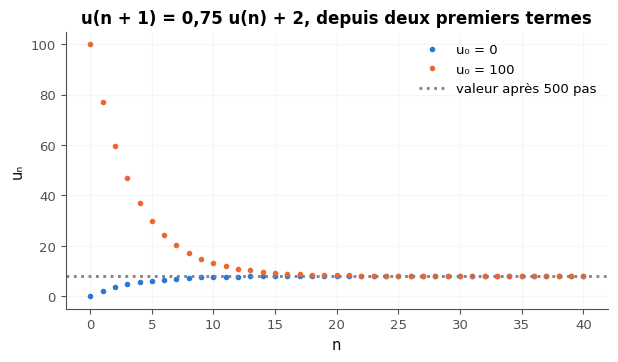

In [26]:
def run(u0, steps):
    """[u(0), …, u(steps)] for u(n + 1) = 0.75 u(n) + 2."""
    terms = [float(u0)]
    for _ in range(steps):
        terms.append(0.75 * terms[-1] + 2)
    return terms


from_0, from_100 = run(0, 40), run(100, 40)
far = run(0, 500)[-1]                                    # the value after 500 steps: where the sequence settles
print("depuis 0   :", [round(u, 3) for u in from_0[:6]], "…", round(from_0[-1], 6))
print("depuis 100 :", [round(u, 3) for u in from_100[:6]], "…", round(from_100[-1], 6))
print("valeur après 500 pas :", far)
print("premier rang à moins de 0,01 de cette valeur, depuis 0 :",
      next(n for n, u in enumerate(from_0) if abs(u - far) < 0.01))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(from_0, "o", markersize=3, label="u₀ = 0")
ax.plot(from_100, "o", markersize=3, label="u₀ = 100")
ax.axhline(far, color="gray", linestyle=":", label="valeur après 500 pas")
ax.set_xlabel("n")
ax.set_ylabel("uₙ")
ax.set_title("u(n + 1) = 0,75 u(n) + 2, depuis deux premiers termes")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

**Après l'expérience.** d) Le premier rang $n$ pour lequel $u_n$ est à moins de 0,01 de sa limite, partie de $u_0 = 0$ (lis-le dans la sortie). Puis, dans ta copie : écris $u_n$ en fonction de $n$ pour $u_0 = 0$ (fiche §5), et compare les deux suites.

In [27]:
answer_R5_18d = next(n for n, u in enumerate(from_0) if abs(u - far) < 0.01)
print(answer_R5_18d)

24


In [28]:
wbm.record("R5.18d", 24, mistakes={"le premier rang où l'écart passe sous 0,01 : lis la ligne « premier rang » de la sortie": {23, 25}})

WBM_ANSWER {"hash": "16cfba195ee22695e8c234bd7c609cdfe000153c8cfc183e420f214b48e4e7a8", "id": "R5.18d", "kind": "int", "magnitude": 1, "mistakes": {"ca30c39403ccfd2af1ac396d1218c1c0bca811a7f8867b785131c0fab506240c": "le premier rang où l'écart passe sous 0,01 : lis la ligne « premier rang » de la sortie", "f7853eb099381d0e2b613704a646e73736cf24e9c4c3488ae38210d620dbffc9": "le premier rang où l'écart passe sous 0,01 : lis la ligne « premier rang » de la sortie"}, "sign": 1}
📝 Ex R5.18d : réponse enregistrée (int).


💡 Le point fixe vérifie $\ell = 0{,}75\,\ell + 2$, soit $\ell = 8$, et $u_n = 8 + (u_0 - 8) \times 0{,}75^n$ : depuis 0, $u_n = 8 - 8 \times 0{,}75^n$ ; depuis 100, $u_n = 8 + 92 \times 0{,}75^n$. L'écart à 8 passe sous 0,01 quand $8 \times 0{,}75^n < 0{,}01$ : 24 pas. Les logarithmes (R6) donneront ce rang sans essais.

### Ex R5.19 — Lisser un signal bruité : l'effet de la fenêtre et de β 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer le compromis d'un lissage : trop peu, il reste du bruit ; trop, la courbe est en retard.  
**Prérequis :** fiche §6 ; R5.16, R5.17 · **Parcours :** C

La cellule ci-dessous fabrique un signal : une **vraie tendance** (une sinusoïde, qu'on ne connaît pas en pratique) à laquelle s'ajoute du **bruit**. Elle donne trois outils : `moving(x, k)` (la moyenne mobile, alignée sur le temps : sa valeur à l'instant $t$ utilise $x_{t-k+1}, \dots, x_t$), `ema(x, beta)` (la moyenne exponentielle) et `error(smoothed)`, l'écart moyen (la racine de la moyenne des carrés des écarts) entre une courbe lissée et la vraie tendance, à partir de $t = 60$.

Calcule :
- a) `window_errors`, la liste des erreurs `error(moving(x, k))` pour chaque fenêtre de `windows` (dans cet ordre) ;
- b) `beta_errors`, la liste des erreurs `error(ema(x, beta))` pour chaque valeur de `betas`.

Puis, en lisant tes listes et la figure :
- c) la fenêtre de `windows` qui donne la plus petite erreur ;
- d) la valeur de `betas` qui donne la plus petite erreur ;
- e) avec une fenêtre de 61, la courbe lissée est-elle en avance (1) ou en retard (2) sur la vraie tendance ?

Dans ta copie : pourquoi l'erreur diminue-t-elle d'abord, puis augmente-t-elle, quand la fenêtre grandit ?

In [29]:
from scipy.signal import lfilter

rng = np.random.default_rng(2026)
t = np.arange(300)
trend = 10 + 4 * np.sin(2 * np.pi * t / 120)           # the true signal, unknown in practice
x = trend + rng.normal(0, 1.5, size=t.size)             # what we measure: the signal plus noise


def moving(x, k):
    """Moving average over k values, aligned on time: entry t is the mean of x[t-k+1..t] (NaN for t < k - 1)."""
    out = np.full(len(x), np.nan)
    out[k - 1:] = np.convolve(x, np.ones(k) / k, mode="valid")
    return out


def ema(x, beta):
    """Exponential moving average v(t) = beta v(t-1) + (1 - beta) x(t), v(0) = 0 (one line of SciPy)."""
    return lfilter([1 - beta], [1, -beta], x)


def error(smoothed, start=60):
    """Root mean square gap between a smoothed curve and the true trend, from time `start` on."""
    return float(np.sqrt(np.mean((smoothed[start:] - trend[start:]) ** 2)))


windows = [1, 3, 9, 25, 61]
betas = [0, 0.5, 0.75, 0.9, 0.99]

In [30]:
window_errors = [error(moving(x, k)) for k in windows]
beta_errors = [error(ema(x, beta)) for beta in betas]
answer_R5_19c = windows[int(np.argmin(window_errors))]
answer_R5_19d = betas[int(np.argmin(beta_errors))]
answer_R5_19e = 2
print("fenêtres :", dict(zip(windows, np.round(window_errors, 3))))
print("β        :", dict(zip(betas, np.round(beta_errors, 3))))

fenêtres : {1: np.float64(1.621), 3: np.float64(1.036), 9: np.float64(0.834), 25: np.float64(1.776), 61: np.float64(3.43)}
β        : {0: np.float64(1.621), 0.5: np.float64(1.011), 0.75: np.float64(0.796), 0.9: np.float64(1.262), 0.99: np.float64(3.135)}


In [31]:
wbm.record("R5.19a", [error(moving(x, k)) for k in windows], decimals=2,
           mistakes={"une erreur par fenêtre, dans l'ordre de windows : error(moving(x, k))":
                         [error(moving(x, k)) for k in reversed(windows)]})
wbm.record("R5.19b", [error(ema(x, beta)) for beta in betas], decimals=2,
           mistakes={"une erreur par valeur de β, dans l'ordre de betas : error(ema(x, beta))":
                         [error(ema(x, beta)) for beta in reversed(betas)]})
wbm.record("R5.19c", 9, choices=[1, 3, 9, 25, 61],
           mistakes={"la plus grande fenêtre lisse le plus, mais la courbe prend du retard : lis la liste des erreurs":
                         61, "une fenêtre de 1 ne lisse rien : l'erreur est celle du bruit": 1,
                     "cherche la plus petite erreur de window_errors": {3, 25}})
wbm.record("R5.19d", 0.75, decimals=2, choices=[0, 0.5, 0.75, 0.9, 0.99],
           mistakes={"un β proche de 1 lisse fort, mais réagit lentement : lis la liste des erreurs": {0.99, 0.9},
                     "β = 0 ne lisse rien : v_t = x_t": 0, "cherche la plus petite erreur de beta_errors": 0.5})
wbm.record("R5.19e", 2, choices=[1, 2],
           mistakes={"la moyenne à l'instant t n'utilise que des valeurs passées : regarde où sont ses sommets": 1})

WBM_ANSWER {"decimals": 2, "element_coarse": [["4f670a5fe7539a1e68b552c9eb9d6d5f9b33eea293544719f71005f885045183"], ["df96222f5f7059b6b7e6ed43bbaac0a305a7e97b72c83ad942bb707243adcef1"], ["9f9d4f73298719855c3ac23261c3b12601fe9066632e21f0beb3eae3322ffd58"], ["487b9713d047242250f6e44129a4827f059c9296c7c0671e7c5da0b86060b23d"], ["1df0f402cde80b23b32216b2b56922590d97ae949e0d7d9f2ce1a4a2dc80ae34"]], "element_coarse_any": [["fb77ff5977bc881ad673da085e946874280278f245dfc7eb57341982405e8607"], ["1a3d6dbd07baeac761ad5b9bfa122ae67a0b598b60a03bc2397a1e616942a4e5"], ["462345d7b5bd21105c923499362e9c806907f8a735776f4c057e82c5fa3b3393"], ["dfe147c7734c16e90db129d43ac82e75fc51cbafe94a25348178b392033fbe15"], ["82b33886ae873416348e7a29a6d1376cf00d61cb79db2087f1b89ccea7a2ddda"]], "element_hashes": ["63d2d7a2aaac613cedd17f8370bfc6dfb9e18b9ceb2c6a9010fc52b5813f2044", "fb5c35f0a05b2b5d3c6d4a8ea912970bade4348069190e0a2e7b43aea7dcd407", "6d9f73a586b084e360a46952506655fa7487fbd261d125654b125b9e0b8de731", "554d3

**La figure** : les erreurs en fonction de la fenêtre et de β, puis deux lissages.

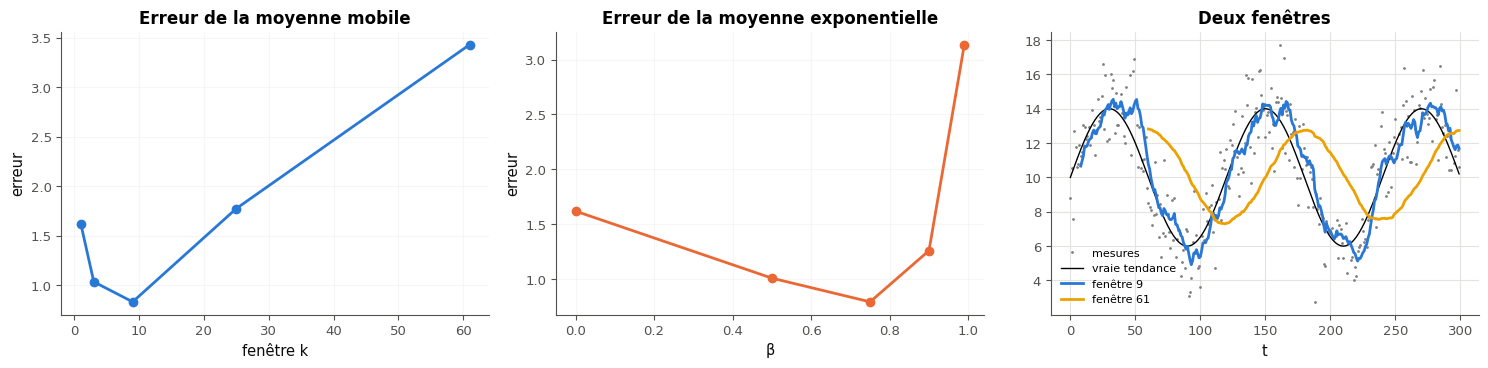

In [32]:
with checked("R5.19 figure"):
    if window_errors is ... or beta_errors is ...:
        print("⏳ Calcule d'abord window_errors et beta_errors.")
    else:
        fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
        axes[0].plot(windows, window_errors, "o-")
        axes[0].set_xlabel("fenêtre k")
        axes[0].set_title("Erreur de la moyenne mobile")
        axes[1].plot(betas, beta_errors, "o-", color="C1")
        axes[1].set_xlabel("β")
        axes[1].set_title("Erreur de la moyenne exponentielle")
        axes[2].plot(t, x, ".", color="gray", markersize=2, label="mesures")
        axes[2].plot(t, trend, color="black", linewidth=1, label="vraie tendance")
        axes[2].plot(t, moving(x, 9), color="C0", label="fenêtre 9")
        axes[2].plot(t, moving(x, 61), color="C3", label="fenêtre 61")
        axes[2].set_xlabel("t")
        axes[2].set_title("Deux fenêtres")
        axes[2].legend(fontsize=8)
        for ax in axes[:2]:
            ax.set_ylabel("erreur")
            ax.grid(True, alpha=0.3)
        fig.tight_layout()
        plt.show()

💡 Une petite fenêtre garde le bruit ; une grande moyenne sur des valeurs trop anciennes : la courbe lissée est **en retard** (la moyenne sur 61 valeurs décrit, à peu près, la tendance d'il y a 30 instants) et aplatit les sommets. Le meilleur réglage est entre les deux, et il dépend du signal : plus la tendance change vite, plus il faut une petite fenêtre (ou un petit β).

### Ex R5.20 — Des suites qui convergent, divergent, oscillent 🎨 ★ ⏱️ 15 min
**Objectif :** voir les comportements d'une suite (converger, osciller, diverger), et reconnaître une limite sur un graphique.  
**Prérequis :** fiche §5 ; R0 (matplotlib) · **Parcours :** C

Complète `plot_sequences(axes)`, qui reçoit **quatre axes** côte à côte et trace, pour $n = 0$ à 30, les termes de :
- (a) $5 - 4 \times 0{,}7^n$ dans `axes[0]` ;
- (b) $2 + 3 \times (-0{,}75)^n$ dans `axes[1]` ;
- (c) $(-1)^n \times \frac{n}{n + 1}$ dans `axes[2]` ;
- (d) $\sqrt{n}$ dans `axes[3]`.

Trace des **points** (une suite n'est définie qu'aux entiers) : `ax.plot(ns, values, "o")`, avec `ns = np.arange(31)` et le calcul vectorisé de NumPy ; un titre par graphique. La cellule de vérification crée les axes, puis la figure s'affiche. Puis :
- a) les lettres des suites qui convergent, dans l'ordre alphabétique (un texte, comme `"bd"`) ;
- b) la liste de leurs limites, dans le même ordre ;
- c) la suite (c) se rapproche tour à tour de deux nombres : la liste de ces deux nombres.

Dans ta copie : pour chaque suite, une phrase qui décrit son comportement (converge en restant du même côté, converge en oscillant, oscille sans limite, tend vers $+\infty$).

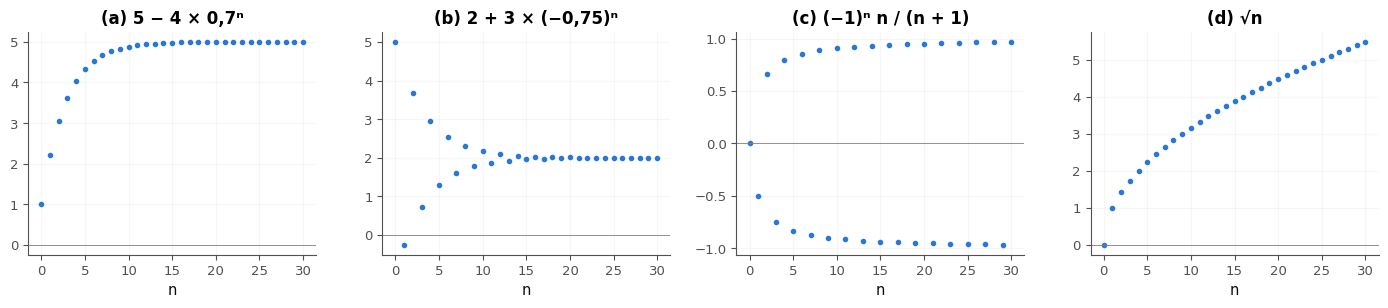

In [33]:
def plot_sequences(axes):
    """Draw the terms of (a), (b), (c), (d) for n = 0 to 30 as points, one sequence in each of the four axes."""
    ns = np.arange(31)
    terms = [5 - 4 * 0.7**ns, 2 + 3 * (-0.75) ** ns, (-1.0) ** ns * ns / (ns + 1), np.sqrt(ns)]
    titles = ["(a) 5 − 4 × 0,7ⁿ", "(b) 2 + 3 × (−0,75)ⁿ", "(c) (−1)ⁿ n / (n + 1)", "(d) √n"]
    for ax, values, title in zip(axes, terms, titles):
        ax.plot(ns, values, "o", markersize=3)
        ax.axhline(0, color="gray", linewidth=0.6)
        ax.set_title(title)
        ax.set_xlabel("n")
        ax.grid(True, alpha=0.3)


fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
plot_sequences(axes)
fig.tight_layout()
plt.show()
answer_R5_20a, answer_R5_20b, answer_R5_20c = "ab", [5, 2], [-1, 1]

In [34]:
wbm.record("R5.20a", "ab",
           mistakes={"(c) se rapproche tour à tour de deux nombres différents : elle n'a pas de limite": {"abc", "c"},
                     "√n grandit sans fin, lentement : elle tend vers +∞, elle ne converge pas": {"abd", "d"},
                     "(b) oscille, mais de moins en moins : l'écart à sa limite est multiplié par −0,75 à chaque pas":
                         "a",
                     "(a) converge : l'écart à sa limite est multiplié par 0,7 à chaque pas": "b"})
wbm.record("R5.20b", [5, 2],
           mistakes={"0,7ⁿ tend vers 0, pas vers 1 : dans (a), le terme 4 × 0,7ⁿ disparaît": [1, 2],
                     "(−0,75)ⁿ tend vers 0, pas vers 1 : dans (b), le terme 3 × (−0,75)ⁿ disparaît": [5, 5],
                     "les limites, pas les coefficients des puissances": [-4, 3]})
wbm.record("R5.20c", [-1, 1], ordered=False,
           mistakes={"n / (n + 1) tend vers 1 : (c) saute entre des valeurs proches de −1 et de 1": [0, 1],
                     "deux nombres seulement : ceux dont les termes de (c) se rapprochent tour à tour": [-1, 0, 1],
                     "(c) n'a pas de limite : ses termes se rapprochent tour à tour de deux nombres": [0]})

WBM_ANSWER {"hash": "d34238c07838484e52cbd16d6338ae29fc02781acd6318522fddbe429235da87", "id": "R5.20a", "kind": "str", "mistakes": {"040fffb43d0e42b45839dc93f012a16baf92a736ed2e47c84ddf00495e784682": "(c) se rapproche tour à tour de deux nombres différents : elle n'a pas de limite", "1de225e3889102f0ecf50de8b6fd1750fcc69669473ecba29501ed83f52d5009": "(a) converge : l'écart à sa limite est multiplié par 0,7 à chaque pas", "35e193c58399e4b78f98b0450365a1f63eb1f066a15aa863f3762a4dbc71fa43": "√n grandit sans fin, lentement : elle tend vers +∞, elle ne converge pas", "771af4dc3631d5b63b7777f526884688afbfcb48ed810796e02fe0532ac9bed7": "(c) se rapproche tour à tour de deux nombres différents : elle n'a pas de limite", "a71f58ac9537aa20b78326261480d3791fa8d2cf442e134514af17cec0e88892": "(b) oscille, mais de moins en moins : l'écart à sa limite est multiplié par −0,75 à chaque pas", "f37d6b21e861779c162a3b95bb15b4df278b3b53489e005408c5424cccec5edc": "√n grandit sans fin, lentement : elle tend v

**Vérifications automatiques** (la figure elle-même se juge à l'œil).

In [35]:
with checked("R5.20 vérifications"):
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
    try:
        created = drawn(plot_sequences, axes)
    finally:
        plt.close(fig)                                     # only the checks below are shown here
    rules = [lambda n: 5 - 4 * 0.7**n, lambda n: 2 + 3 * (-0.75) ** n, lambda n: (-1) ** n * n / (n + 1),
             lambda n: math.sqrt(n)]
    problems = []
    if created:
        problems.append("ta fonction ouvre sa propre figure : dessine dans les axes reçus (axes[0].plot, …)")
    else:
        for k, (name, ax, rule) in enumerate(zip("abcd", axes, rules)):
            points = []
            for line in ax.lines:
                points += list(zip(np.asarray(line.get_xdata(), dtype=float), np.asarray(line.get_ydata(), dtype=float)))
            for collection in ax.collections:
                points += [tuple(p) for p in np.asarray(collection.get_offsets(), dtype=float)]
            at_integers = {n: [py for px, py in points if abs(px - n) < 1e-9] for n in range(21)}
            if not points:
                problems.append(f"rien n'est tracé dans axes[{k}] : dessine ({name}) avec axes[{k}].plot(...), pas plt.plot")
                continue
            wrong = [n for n, ys in at_integers.items() if ys and not any(abs(y - rule(n)) < 1e-6 for y in ys)]
            missing = [n for n, ys in at_integers.items() if not ys]
            if wrong:
                problems.append(f"les termes de ({name}) dans axes[{k}] ne sont pas les bons (dès le rang {wrong[0]})")
            elif missing:
                problems.append(f"il manque des termes de ({name}) dans axes[{k}] (au moins celui de rang {missing[0]})")
    if problems:
        print("❌ Ex R5.20 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex R5.20 : les quatre suites sont tracées, chacune dans son graphique.")

✅ Ex R5.20 : les quatre suites sont tracées, chacune dans son graphique.


💡 (a) converge vers 5 en restant en dessous ; (b) converge vers 2 en oscillant autour ; (c) n'a pas de limite : ses termes pairs tendent vers 1, ses termes impairs vers −1 ; (d) tend vers $+\infty$, si lentement qu'on pourrait croire, sur 30 termes, qu'elle se stabilise : il faut $n = 10\,000$ pour atteindre 100.

## Partie C · Indices et temps de calcul

Fiche §4. Deux décalages d'indice à trouver, puis une boucle et une formule chronométrées.

### Ex R5.21 — Chasse à l'erreur : un décalage d'indice dans une somme 🐛 ★ ⏱️ 15 min
**Objectif :** repérer un décalage d'indice dans une boucle et dans une formule de somme, puis le corriger.  
**Prérequis :** fiche §4 ; R4 §5 (bornes d'un range) · **Parcours :** C, E

Une épargnante dépose `first` euros la première année, puis augmente son dépôt de `rate` (2 % s'écrit `0.02`) chaque année : ses dépôts sont `first`, `first*(1 + rate)`, `first*(1 + rate)**2`, … Les deux fonctions ci-dessous doivent calculer le total de ses `years` premiers dépôts, l'une avec une boucle, l'autre avec la formule de la fiche §4. Elles contiennent chacune une erreur d'indice. **Sans rien exécuter d'abord**, trouve-les.

```python
def total_savings(first, rate, years):
    """The total of `years` yearly deposits that grow by `rate` each year: first, first*(1 + rate), …"""
    q = 1 + rate                                        # (A)
    total = 0                                           # (B)
    for k in range(1, years):                           # (C)
        total += first * q**k                           # (D)
    return total                                        # (E)


def total_formula(first, rate, years):
    """The same total, with the formula of the sum of a geometric sequence."""
    q = 1 + rate                                        # (F)
    return first * (1 - q ** (years - 1)) / (1 - q)    # (G)
```

- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) combien de dépôts la boucle fautive additionne-t-elle pour `years = 10` ?

Puis corrige les deux fonctions dans la cellule ci-dessous (elle contient le code fautif) : la vérification calcule c), la liste `[total_savings(1000, 0.02, 5), total_formula(1000, 0.02, 5)]`, qui doit donner deux fois le même total.

In [36]:
answer_R5_21a = "CG"
answer_R5_21b = len(range(1, 10))

def total_savings(first, rate, years):
    """The total of `years` yearly deposits that grow by `rate` each year: first, first*(1 + rate), …"""
    q = 1 + rate                                        # (A)
    total = 0                                           # (B)
    for k in range(years):                              # (C) corrected: k = 0, 1, …, years - 1
        total += first * q**k                           # (D)
    return total                                        # (E)


def total_formula(first, rate, years):
    """The same total, with the formula of the sum of a geometric sequence."""
    q = 1 + rate                                        # (F)
    return first * (1 - q**years) / (1 - q)            # (G) corrected: years terms, so q**years


print(answer_R5_21a, answer_R5_21b, [total_savings(1000, 0.02, 5), total_formula(1000, 0.02, 5)])

CG 9 [5204.0401600000005, 5204.040159999996]


In [37]:
wbm.record("R5.21a", "CG",
           mistakes={"il manque une ligne fautive : compte les tours de la boucle pour years = 3 : combien de dépôts sont ajoutés ?": "G",
                     "il manque une ligne fautive : dans la formule, l'exposant est le nombre de termes": "C",
                     "une ligne de trop : la ligne (A) est correcte ; relis ce qu'elle fait": "ACG",
                     "une ligne de trop : la ligne (B) est correcte ; relis ce qu'elle fait": "BCG",
                     "une ligne de trop : la ligne (D) est correcte ; relis ce qu'elle fait": "CDG",
                     "une ligne de trop : la ligne (E) est correcte ; relis ce qu'elle fait": "CEG",
                     "une ligne de trop : la ligne (F) est correcte ; relis ce qu'elle fait": "CFG",
                     "la ligne (A) est correcte, et il manque une ligne fautive : compte les tours de la boucle pour years = 3 : combien de dépôts sont ajoutés ?": "AG",
                     "la ligne (B) est correcte, et il manque une ligne fautive : compte les tours de la boucle pour years = 3 : combien de dépôts sont ajoutés ?": "BG",
                     "la ligne (D) est juste si la boucle part de k = 0 : c'est la boucle qui saute un dépôt": "DG",
                     "la ligne (E) est correcte, et il manque une ligne fautive : compte les tours de la boucle pour years = 3 : combien de dépôts sont ajoutés ?": "EG",
                     "la ligne (F) est correcte, et il manque une ligne fautive : compte les tours de la boucle pour years = 3 : combien de dépôts sont ajoutés ?": "FG",
                     "la ligne (A) est correcte, et il manque une ligne fautive : dans la formule, l'exposant est le nombre de termes": "AC",
                     "la ligne (B) est correcte, et il manque une ligne fautive : dans la formule, l'exposant est le nombre de termes": "BC",
                     "la ligne (D) est correcte, et il manque une ligne fautive : dans la formule, l'exposant est le nombre de termes": "CD",
                     "la ligne (E) est correcte, et il manque une ligne fautive : dans la formule, l'exposant est le nombre de termes": "CE",
                     "la ligne (F) est correcte, et il manque une ligne fautive : dans la formule, l'exposant est le nombre de termes": "CF",
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"A", "B", "D", "E", "F", "AB", "AD", "AE", "AF", "BD", "BE", "BF", "DE", "DF", "EF", "ABC", "ABD", "ABE", "ABF", "ABG", "ACD", "ACE", "ACF", "ADE", "ADF", "ADG", "AEF", "AEG", "AFG", "BCD", "BCE", "BCF", "BDE", "BDF", "BDG", "BEF", "BEG", "BFG", "CDE", "CDF", "CEF", "DEF", "DEG", "DFG", "EFG", "ABCD", "ABCE", "ABCF", "ABDE", "ABDF", "ABDG", "ABEF", "ABEG", "ABFG", "ACDE", "ACDF", "ACEF", "ADEF", "ADEG", "ADFG", "AEFG", "BCDE", "BCDF", "BCEF", "BDEF", "BDEG", "BDFG", "BEFG", "CDEF", "DEFG", "ABCDE", "ABCDF", "ABCEF", "ABDEF", "ABDEG", "ABDFG", "ABEFG", "ACDEF", "ADEFG", "BCDEF", "BDEFG", "ABCDEF", "ABDEFG"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCG", "ACDG", "ACEG", "ACFG", "BCDG", "BCEG", "BCFG", "CDEG", "CDFG", "CEFG", "ABCDG", "ABCEG", "ABCFG", "ACDEG", "ACDFG", "ACEFG", "BCDEG", "BCDFG", "BCEFG", "CDEFG", "ABCDEG", "ABCDFG", "ABCEFG", "ACDEFG", "BCDEFG", "ABCDEFG"}})
wbm.record("R5.21b", 9,
           mistakes={"range(1, years) va de 1 à years − 1 : la borne de droite est exclue": {10, 11}})
wbm.record("R5.21c", [5204.04016, 5204.04016], decimals=4,
           mistakes={"la boucle saute encore le premier dépôt : k doit partir de 0": [4204.04016, 5204.04016],
                     "la formule : l'exposant de q est le nombre de dépôts": [5204.04016, 4121.608],
                     "les deux fonctions sont encore fausses : relis a)": [4204.04016, 4121.608],
                     "avec k de 1 à years, le dépôt de rang k est first × q**(k − 1) : le plus simple est de faire "
                     "partir k de 0": [5308.1209632, 5204.04016],
                     "la boucle : avec k de 1 à years, le dépôt est first × q**(k − 1) ; la formule : l'exposant de q "
                     "est le nombre de dépôts": [5308.1209632, 4121.608]})

WBM_ANSWER {"hash": "b08f1d27d9884346d0b6f685b905f4ffe61f7be5ec57ab494f139ea5aa0946a0", "id": "R5.21a", "kind": "str", "mistakes": {"006b562f81275d258fe3c1f1c80380a8b8619d6abd13c521c274815cd47d99a7": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "00f52ce5af840915c370fc03d297f8ec2111e37c1f29fd96dc06dd48f53bf14c": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "04d9954dff1f5d813fb1406de65839f1bf6f5db61515f7abdceb4bb4a56ea930": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "05275a883f1e6228ba25e651ff71223aa730b94d59186652df4a1818209a1afe": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "05d6ca11400b1b7e7095615387c362b56c0d68e69ca7da4bba7a7ca18c4d3178": "il manque des lignes fautives, et des l

💡 Les deux erreurs sont le même décalage d'indice, sous deux formes : `range(1, years)` n'a que `years − 1` tours et oublie le dépôt de rang 0 ; la formule utilise $q^{n-1}$ au lieu de $q^n$, où $n$ est le **nombre** de termes. Le réflexe qui les attrape : tester avec `years = 1` (un seul dépôt, le total vaut `first`) et `years = 2`.

### Ex R5.22 — Une boucle ou une formule ? Mesurer le temps de calcul 🛠️ ★ ⏱️ 15 min
**Objectif :** mesurer le temps d'un calcul avec `time.perf_counter`, et voir ce qu'une formule fait gagner sur une boucle.  
**Prérequis :** fiche §4 ; R5.14 · **Parcours :** C

`time.perf_counter()` rend un temps en secondes, très précis : la durée d'un calcul est la différence entre la valeur lue juste après et la valeur lue juste avant. Complète la cellule : pour $n = 10^3$, $10^4$, $10^5$ et $10^6$, et $q = 0{,}999\,999$, mesure le temps de `loop_sum(q, n)` et celui de `formula_sum(q, n)`, et affiche $n$, les deux temps et l'écart entre les deux résultats.

Puis, dans ta copie :
1. Quand $n$ est multiplié par 10, par combien le temps de la boucle est-il (à peu près) multiplié ? Et celui de la formule ?
2. Les deux résultats sont-ils exactement égaux ? D'où vient l'écart (R1 : les flottants) ?
3. Pourquoi les temps changent-ils un peu d'une exécution à l'autre ?

In [38]:
def loop_sum(q, n):
    """1 + q + … + q**(n - 1), added term by term."""
    total = 0.0
    for k in range(n):
        total += q**k
    return total


def formula_sum(q, n):
    """The same sum with the formula (q != 1)."""
    return (1 - q**n) / (1 - q)


# For n = 10**3, 10**4, 10**5 and 10**6, with q = 0.999999: measure the time of each function with
# time.perf_counter() (before and after the call), and print n, the two times and the gap between the two results.
for n in [10**3, 10**4, 10**5, 10**6]:
    start = time.perf_counter()
    by_loop = loop_sum(0.999999, n)
    middle = time.perf_counter()
    by_formula = formula_sum(0.999999, n)
    end = time.perf_counter()
    print(f"n = {n:>9,} : boucle {middle - start:.5f} s, formule {end - middle:.7f} s, "
          f"écart {abs(by_loop - by_formula):.1e}")

n =     1,000 : boucle 0.00006 s, formule 0.0000015 s, écart 3.4e-11
n =    10,000 : boucle 0.00059 s, formule 0.0000009 s, écart 1.3e-11
n =   100,000 : boucle 0.00666 s, formule 0.0000019 s, écart 2.9e-11
n = 1,000,000 : boucle 0.05442 s, formule 0.0000034 s, écart 3.1e-08


💡 Le temps de la boucle est proportionnel à $n$ (chaque terme coûte une puissance et une addition) ; celui de la formule ne dépend presque pas de $n$. Les résultats diffèrent dans les derniers chiffres : les arrondis des flottants ne tombent pas au même endroit. Les temps varient d'une exécution à l'autre, parce que l'ordinateur fait autre chose en même temps : on mesure plusieurs fois (le module `timeit` le fait) et l'on garde l'ordre de grandeur.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Calcules-tu les termes d'une suite explicite ou par récurrence, et reconnais-tu une suite arithmétique ou géométrique ?
2. Calcules-tu une somme de termes, et une somme infinie géométrique, en comptant bien les termes ?
3. Sais-tu dire si une suite converge, et calculer une moyenne mobile et une moyenne exponentielle ?

**La suite** : R6, *Exponentielle et logarithmes*. Dans workbookIA, continue le chapitre 0A au rythme de ton tableau de bord.